<a href="https://colab.research.google.com/github/saivvyy/EDAV-COURSE-END-PROJECT/blob/main/Fertilizer_Usage_and_Crop_Productivity_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
# Fertilizer Usage and Crop Productivity Analysis

This project analyzes crop productivity data. We will start with basic operations, load our dataset, clean it up, perform groups and aggregations, and finally visualize the patterns using clean plots.
```

In [1]:
# CO1: NumPy Array Operations
import numpy as np

# Create array
yield_array = np.array([2.5, 3.1, 1.8, 4.2, 3.8])
print("Original Yield Array:", yield_array)

# Scale yields
scaled_array = yield_array * 1.1
print("Scaled Yield Array:", scaled_array)

# Filter yields
high_yields = yield_array[yield_array > 3.0]
print("Yields above 3.0:", high_yields)

Original Yield Array: [2.5 3.1 1.8 4.2 3.8]
Scaled Yield Array: [2.75 3.41 1.98 4.62 4.18]
Yields above 3.0: [3.1 4.2 3.8]


In [2]:
# CO1: Additional NumPy Techniques
import numpy as np

# Matrix operations
matrix_2d = np.array([[10, 20, 30], [40, 50, 60]])
print("Original:\n", matrix_2d)
print("Transposed:\n", matrix_2d.T)
print("Swapped:\n", np.swapaxes(matrix_2d, 0, 1))

# Math functions
print("\nExponential on sample yields:", np.exp(yield_array[:3]))
print("Square root of yields:", np.sqrt(yield_array))

# Random generation
np.random.seed(42)
simulated_growth = np.random.normal(loc=0.5, scale=0.1, size=5)
print("\nSimulated multipliers:", simulated_growth)

Original:
 [[10 20 30]
 [40 50 60]]
Transposed:
 [[10 40]
 [20 50]
 [30 60]]
Swapped:
 [[10 40]
 [20 50]
 [30 60]]

Exponential on sample yields: [12.18249396 22.19795128  6.04964746]
Square root of yields: [1.58113883 1.76068169 1.34164079 2.04939015 1.94935887]

Simulated multipliers: [0.54967142 0.48617357 0.56476885 0.65230299 0.47658466]


In [3]:
# CO2: Load & Review Data
import pandas as pd

# Load dataset
df = pd.read_csv('/content/crop_yield.csv')

# Clean column headers
df.columns = df.columns.str.strip()

# Preview data
display(df.head())

# Show info
print("Dataset Summary:")
df.info()

,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,2051.4,7024878.38,22882.34,0.796087
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,2051.4,631643.29,2057.47,0.710435
2,Castor seed,1997,Kharif,Assam,796.0,22,2051.4,75755.32,246.76,0.238333
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,2051.4,1870661.52,6093.36,5238.051739
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,2051.4,165500.63,539.09,0.420909


Dataset Summary:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19689 entries, 0 to 19688
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Crop             19689 non-null  object 
 1   Crop_Year        19689 non-null  int64  
 2   Season           19689 non-null  object 
 3   State            19689 non-null  object 
 4   Area             19689 non-null  float64
 5   Production       19689 non-null  int64  
 6   Annual_Rainfall  19689 non-null  float64
 7   Fertilizer       19689 non-null  float64
 8   Pesticide        19689 non-null  float64
 9   Yield            19689 non-null  float64
dtypes: float64(5), int64(2), object(3)
memory usage: 1.5+ MB


In [4]:
# CO2: Reindexing & Export

# Reindex series
yearly_series = df.groupby('Crop_Year')['Yield'].mean()
target_years = [1995, 2000, 2005, 2010, 2025]
reindexed_series = yearly_series.reindex(target_years, fill_value=0.0)
print("Reindexed averages:\n", reindexed_series)

# Drop columns
simplified_df = df.drop(columns=['State', 'Pesticide'])
print("\nRemaining columns:", list(simplified_df.columns))

# Export CSV
simplified_df.head(100).to_csv('/content/crop_subset_summary.csv', index=False)
print("\nSaved first 100 rows.")

Reindexed averages:
 Crop_Year
1995     0.000000
2000    75.572901
2005    86.486543
2010    72.177623
2025     0.000000
Name: Yield, dtype: float64

Remaining columns: ['Crop', 'Crop_Year', 'Season', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Yield']

Saved first 100 rows.


In [5]:
# CO3: Clean & Prep Data

# Check missing values
missing_sums = df.isnull().sum()
print("Missing Value Count:")
print(missing_sums)

# Bin rainfall
rain_ranges = [0, 600, 1500, 15000]
rain_labels = ['Low Rain', 'Medium Rain', 'High Rain']
df['Rain_Category'] = pd.cut(df['Annual_Rainfall'], bins=rain_ranges, labels=rain_labels)

# Map seasons
season_mapping = {
    'Kharif': 'Summer',
    'Rabi': 'Winter',
    'Whole Year': 'Full Year'
}
df['Simple_Season'] = df['Season'].map(season_mapping).fillna('Other')

# Verify counts
print("\nRainfall category counts:")
print(df['Rain_Category'].value_counts())

print("\nSimplified Season counts:")
print(df['Simple_Season'].value_counts())

Missing Value Count:
Crop               0
Crop_Year          0
Season             0
State              0
Area               0
Production         0
Annual_Rainfall    0
Fertilizer         0
Pesticide          0
Yield              0
dtype: int64

Rainfall category counts:
Rain_Category
Medium Rain    12121
High Rain       6242
Low Rain        1326
Name: count, dtype: int64

Simplified Season counts:
Simple_Season
Other    19689
Name: count, dtype: int64


In [6]:
# CO3: Multi-Index & Reshape

# Create multi-index
multi_indexed_df = df.set_index(['State', 'Crop']).sort_index()
print("Multi-indexed head:")
display(multi_indexed_df.head(3))

# Reorder levels
reordered_df = multi_indexed_df.reorder_levels(['Crop', 'State']).sort_index()
print("\nReordered hierarchy:")
display(reordered_df.head(3))

# Unstack pivot
grouped_metrics = df.groupby(['Crop', 'Rain_Category'], observed=False)['Yield'].mean()
pivoted_yields = grouped_metrics.unstack(level='Rain_Category')
print("\nUnstacked rainfall pivot:")
display(pivoted_yields.head(5))

Multi-indexed head:


Crop_Year       Season   Area  Production  \
State          Crop                                                  
Andhra Pradesh Arecanut       2000  Whole Year   262.0         724   
               Arecanut       2001  Whole Year   268.0         449   
               Arecanut       2002  Whole Year   296.0         427   

                         Annual_Rainfall  Fertilizer  Pesticide   Yield  \
State          Crop                                                       
Andhra Pradesh Arecanut            935.6    25720.54      68.12  2.7800   
               Arecanut            928.4    27370.84      69.68  1.7100   
               Arecanut            648.1    28022.32      74.00  1.4525   

                        Rain_Category Simple_Season  
State          Crop                                  
Andhra Pradesh Arecanut   Medium Rain         Other  
               Arecanut   Medium Rain         Other  
               Arecanut   Medium Rain         Other


Reordered hierarchy:


Crop_Year       Season   Area  Production  \
Crop     State                                                       
Arecanut Andhra Pradesh       2000  Whole Year   262.0         724   
         Andhra Pradesh       2001  Whole Year   268.0         449   
         Andhra Pradesh       2002  Whole Year   296.0         427   

                         Annual_Rainfall  Fertilizer  Pesticide   Yield  \
Crop     State                                                            
Arecanut Andhra Pradesh            935.6    25720.54      68.12  2.7800   
         Andhra Pradesh            928.4    27370.84      69.68  1.7100   
         Andhra Pradesh            648.1    28022.32      74.00  1.4525   

                        Rain_Category Simple_Season  
Crop     State                                       
Arecanut Andhra Pradesh   Medium Rain         Other  
         Andhra Pradesh   Medium Rain         Other  
         Andhra Pradesh   Medium Rain         Other


Unstacked rainfall pivot:


Rain_Category,Low Rain,Medium Rain,High Rain
Crop,,,
Arecanut,0.000000,3.307312,1.229452
Arhar/Tur,0.908206,1.003488,0.914047
Bajra,1.502169,2.555199,2.493682
Banana,40.253390,36.808382,11.528563
Barley,2.720592,1.442237,1.179570


In [7]:
# CO4: Aggregations & Trends

# Aggregate metrics
crop_groups = df.groupby(['Crop', 'Rain_Category'], observed=False).agg({
    'Yield': 'mean',
    'Pesticide': 'mean'
}).reset_index()

print("Grouped Crop Metrics:")
display(crop_groups.head(10))

# Convert dates
df['Year_Date'] = pd.to_datetime(df['Crop_Year'].astype(str) + '-01-01')

# Index by date
time_df = df.set_index('Year_Date').sort_index()

# Calculate annual average
annual_yield_trend = time_df.groupby('Crop_Year')['Yield'].mean()
print("\nAnnual Yield Trends:")
print(annual_yield_trend.head(10))

Grouped Crop Metrics:


,Crop,Rain_Category,Yield,Pesticide
0,Arecanut,Low Rain,0.000000,1245.780000
1,Arecanut,Medium Rain,3.307312,19752.799403
2,Arecanut,High Rain,1.229452,12107.998867
3,Arhar/Tur,Low Rain,0.908206,18313.088000
4,Arhar/Tur,Medium Rain,1.003488,69060.220153
5,Arhar/Tur,High Rain,0.914047,4993.213053
6,Bajra,Low Rain,1.502169,79641.503333
7,Bajra,Medium Rain,2.555199,48664.186218
8,Bajra,High Rain,2.493682,4420.829836
9,Banana,Low Rain,40.253390,5987.940000



Annual Yield Trends:
Crop_Year
1997    63.872577
1998    55.938462
1999    76.943722
2000    75.572901
2001    75.441594
2002    80.656215
2003    83.694593
2004    81.201928
2005    86.486543
2006    77.479036
Name: Yield, dtype: float64


In [8]:
# CO4: Advanced Aggregations

# Crop statistics
crop_stats = df.groupby('Crop', as_index=False).agg({
    'Yield': ['mean', 'max'],
    'Fertilizer': ['sum', 'mean']
})
print("Crop yield statistics:")
display(crop_stats.head(5))

# Generate date range
monthly_range = pd.date_range(start='2020-01-01', periods=12, freq='ME')
print("\nSample monthly timeline:")
print(monthly_range[:5])

# Calculate annual average
yearly_yield = df.groupby('Crop_Year')['Yield'].mean()
yearly_yield.index = pd.to_datetime(yearly_yield.index.astype(str) + '-01-01')

# Resample quarterly
quarterly_yield = yearly_yield.resample('QE').interpolate(method='linear')
print("\nQuarterly yield estimates:")
print(quarterly_yield.head(8))

Crop yield statistics:


Crop      Yield                Fertilizer              
                   mean         max           sum          mean
0   Arecanut   2.073635   10.948182  1.227541e+09  7.577416e+06
1  Arhar/Tur   0.967348   68.230000  1.121027e+10  2.206746e+07
2      Bajra   2.427462   74.303077  1.205114e+10  2.299835e+07
3     Banana  26.851128  126.387692  9.805911e+08  4.002412e+06
4     Barley   1.595540    3.988235  1.190739e+09  4.009223e+06


Sample monthly timeline:
DatetimeIndex(['2020-01-31', '2020-02-29', '2020-03-31', '2020-04-30',
               '2020-05-31'],
              dtype='datetime64[ns]', freq='ME')

Quarterly yield estimates:
Crop_Year
1997-03-31   NaN
1997-06-30   NaN
1997-09-30   NaN
1997-12-31   NaN
1998-03-31   NaN
1998-06-30   NaN
1998-09-30   NaN
1998-12-31   NaN
Freq: QE-DEC, Name: Yield, dtype: float64


/tmp/ipykernel_28145/3029098225.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


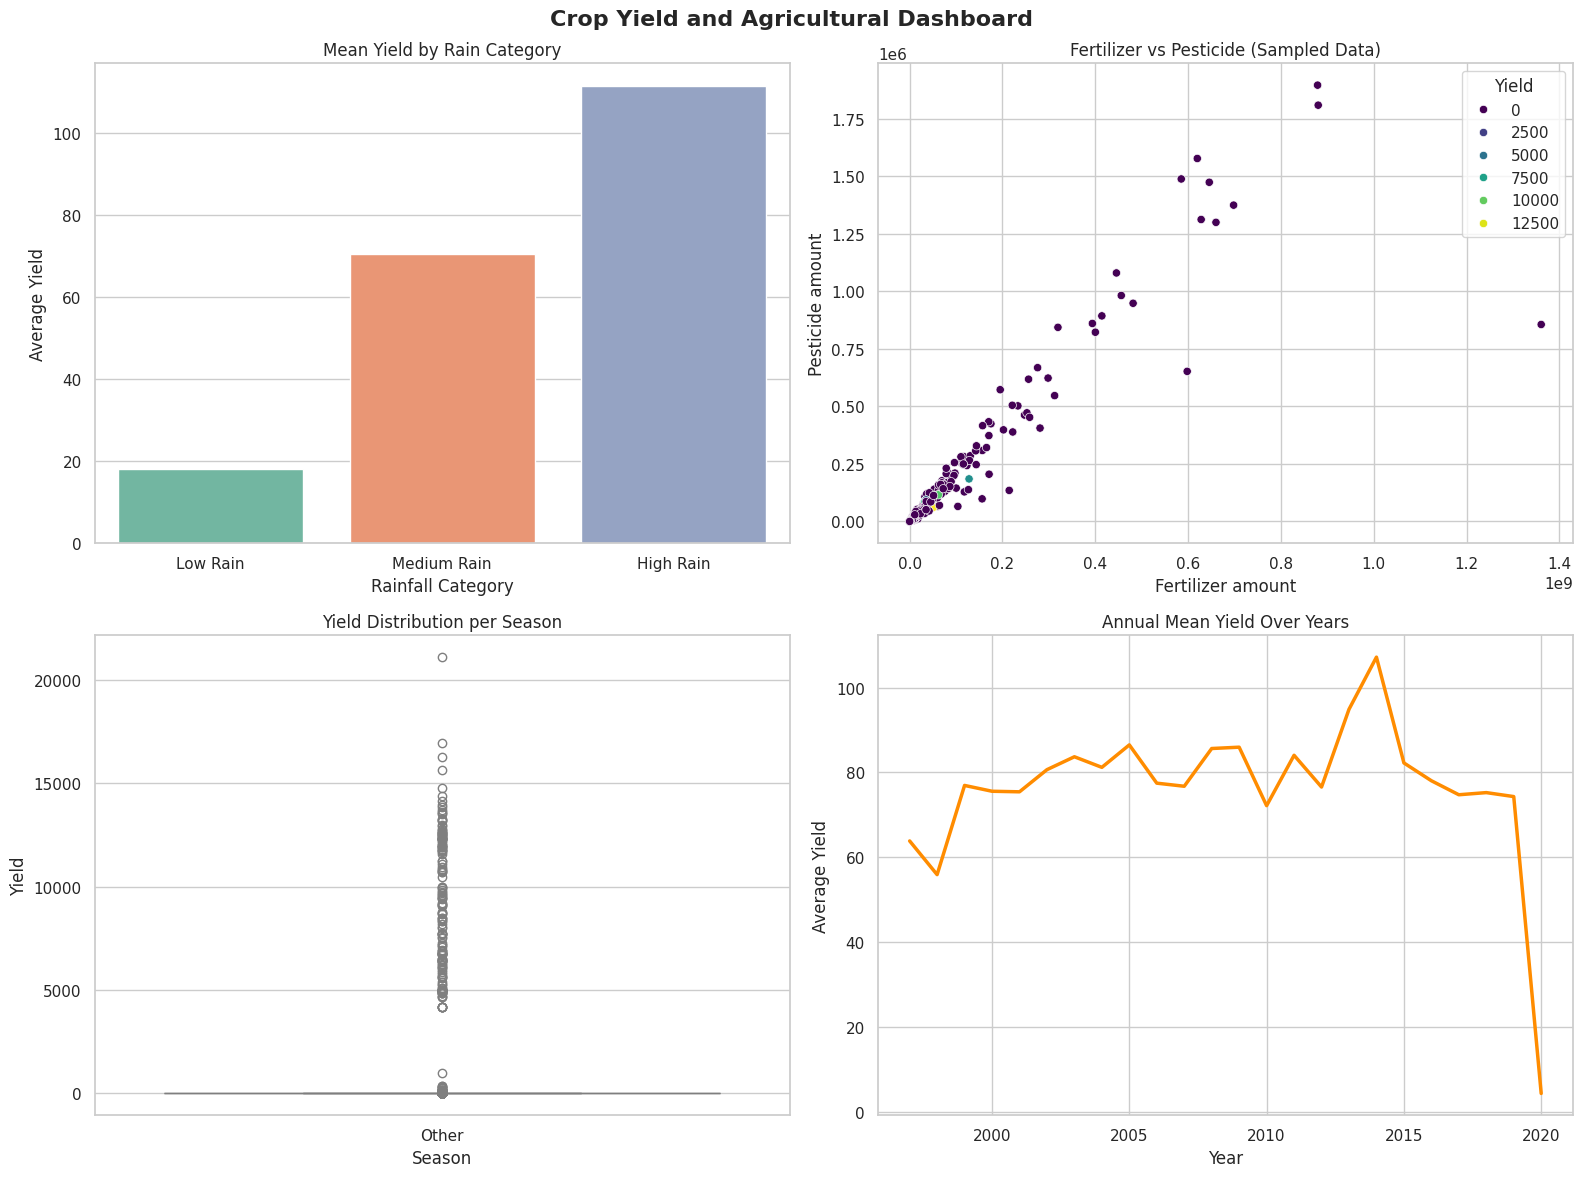

In [9]:
# CO5: Visualizations & Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Set theme
sns.set_theme(style="whitegrid")

# Create subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot bar chart
sns.barplot(
    ax=axes[0, 0],
    data=df,
    x='Rain_Category',
    y='Yield',
    palette='Set2',
    errorbar=None
)
axes[0, 0].set_title('Mean Yield by Rain Category')
axes[0, 0].set_xlabel('Rainfall Category')
axes[0, 0].set_ylabel('Average Yield')

# Plot scatter
sns.scatterplot(
    ax=axes[0, 1],
    data=df.sample(1000, random_state=1),
    x='Fertilizer',
    y='Pesticide',
    hue='Yield',
    palette='viridis'
)
axes[0, 1].set_title('Fertilizer vs Pesticide (Sampled Data)')
axes[0, 1].set_xlabel('Fertilizer amount')
axes[0, 1].set_ylabel('Pesticide amount')

# Plot boxplot
sns.boxplot(
    ax=axes[1, 0],
    data=df,
    x='Simple_Season',
    y='Yield',
    palette='Pastel1',
    hue='Simple_Season',
    legend=False
)
axes[1, 0].set_title('Yield Distribution per Season')
axes[1, 0].set_xlabel('Season')
axes[1, 0].set_ylabel('Yield')

# Plot line
sns.lineplot(
    ax=axes[1, 1],
    data=df.groupby('Crop_Year')['Yield'].mean().reset_index(),
    x='Crop_Year',
    y='Yield',
    color='darkorange',
    linewidth=2.5
)
axes[1, 1].set_title('Annual Mean Yield Over Years')
axes[1, 1].set_xlabel('Year')
axes[1, 1].set_ylabel('Average Yield')

# Adjust layout
plt.suptitle('Crop Yield and Agricultural Dashboard', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

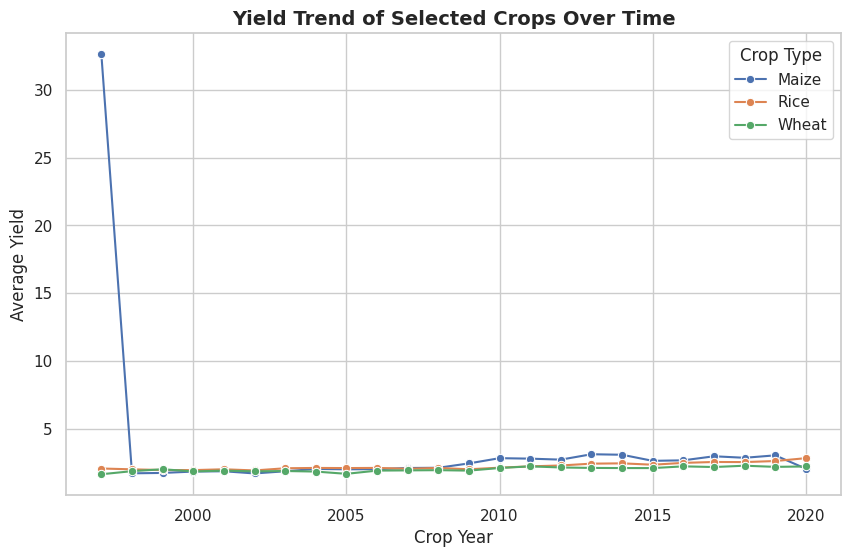

In [10]:
# CO5: Crop Yield Comparison

# Filter crops
selected_crops = df[df['Crop'].isin(['Rice', 'Wheat', 'Maize'])]

# Create line plot
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=selected_crops,
    x='Crop_Year',
    y='Yield',
    hue='Crop',
    errorbar=None,
    marker='o'
)
plt.title('Yield Trend of Selected Crops Over Time', fontsize=14, fontweight='bold')
plt.xlabel('Crop Year')
plt.ylabel('Average Yield')
plt.legend(title='Crop Type')
plt.show()

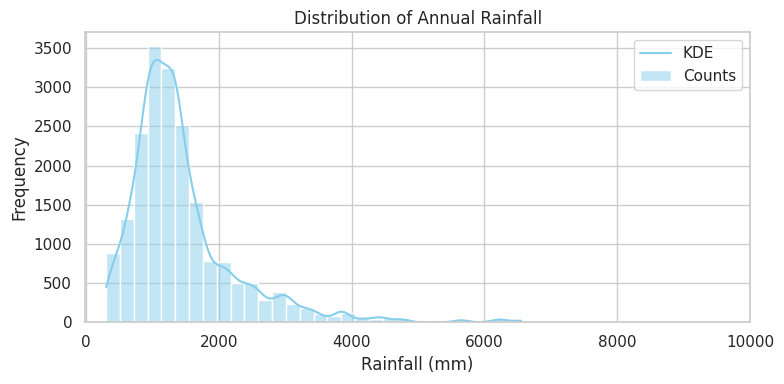

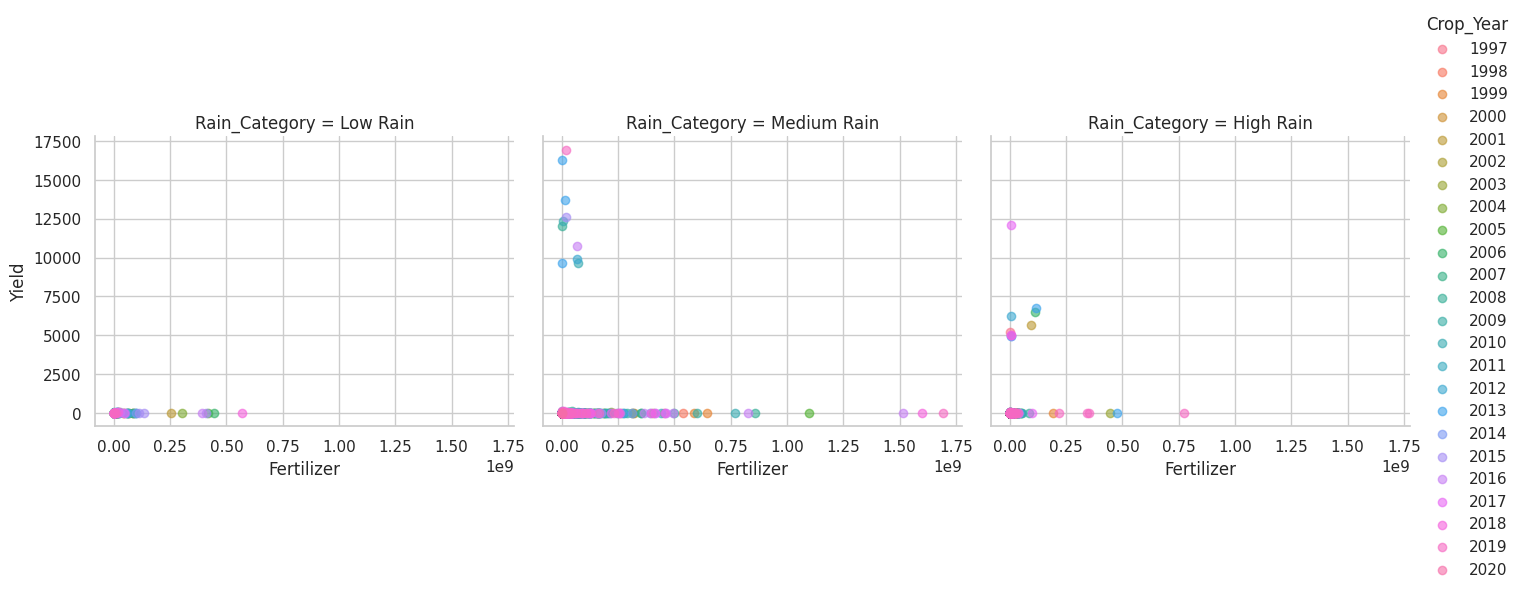

In [11]:
# CO5: Ticks and Facet Grids

# Plot distribution
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df['Annual_Rainfall'], kde=True, color='skyblue', bins=30, ax=ax)
ax.set_title("Distribution of Annual Rainfall", fontsize=12)
ax.set_xlabel("Rainfall (mm)")
ax.set_ylabel("Frequency")
ax.set_xticks([0, 2000, 4000, 6000, 8000, 10000])
ax.legend(['KDE', 'Counts'])
plt.tight_layout()
plt.savefig('/content/rainfall_distribution.png', dpi=150)
plt.show()

# Facet plot
grid = sns.FacetGrid(df.sample(2000, random_state=42), col="Rain_Category", hue="Crop_Year", height=4, aspect=1.2)
grid.map(plt.scatter, "Fertilizer", "Yield", alpha=0.6)
grid.add_legend()
plt.show()

### Part 1: Exploratory Data Analysis (EDA) (Plots 1 to 10)

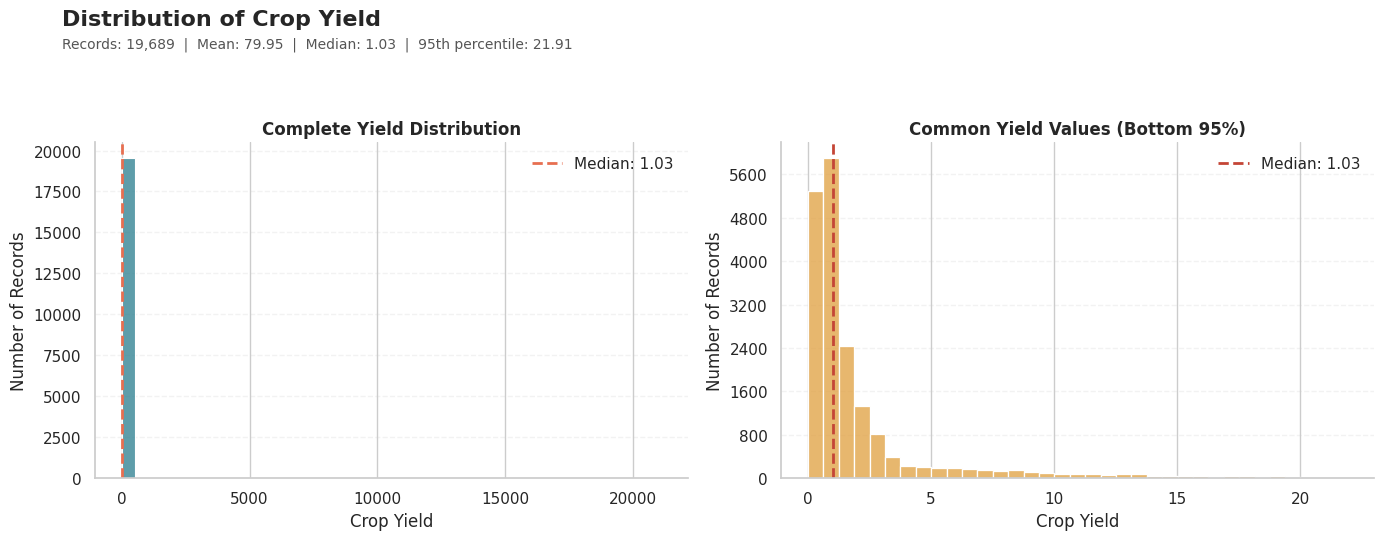

In [12]:
# 1. Distribution of Crop Yield
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.ticker import MaxNLocator

yield_data = df["Yield"].dropna()
p95 = yield_data.quantile(0.95)
mean_yield = yield_data.mean()
median_yield = yield_data.median()

sns.set_theme(style="whitegrid", context="notebook")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Panel 1: Complete distribution
sns.histplot(
    yield_data, bins=40, color="#287D8E",
    edgecolor="white", ax=axes[0]
)
axes[0].axvline(
    median_yield, color="#E76F51", linestyle="--",
    linewidth=2, label=f"Median: {median_yield:,.2f}"
)
axes[0].set_title("Complete Yield Distribution", fontweight="bold")
axes[0].set_xlabel("Crop Yield")
axes[0].set_ylabel("Number of Records")
axes[0].legend(frameon=False)

# Panel 2: Zoom into the bottom 95%
zoom_data = yield_data[yield_data <= p95]

sns.histplot(
    zoom_data, bins=35, color="#E09F3E",
    edgecolor="white", ax=axes[1]
)
axes[1].axvline(
    median_yield, color="#C44536", linestyle="--",
    linewidth=2, label=f"Median: {median_yield:,.2f}"
)

if mean_yield <= p95:
    axes[1].axvline(
        mean_yield, color="#5B4B8A", linestyle=":",
        linewidth=2.2, label=f"Mean: {mean_yield:,.2f}"
    )

axes[1].set_title("Common Yield Values (Bottom 95%)", fontweight="bold")
axes[1].set_xlabel("Crop Yield")
axes[1].set_ylabel("Number of Records")
axes[1].legend(frameon=False)

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))

fig.suptitle(
    "Distribution of Crop Yield",
    fontsize=16, fontweight="bold", x=0.05, ha="left"
)

fig.text(
    0.05, 0.91,
    f"Records: {len(yield_data):,}  |  Mean: {mean_yield:,.2f}  |  "
    f"Median: {median_yield:,.2f}  |  95th percentile: {p95:,.2f}",
    fontsize=10, color="#555555"
)

plt.tight_layout(rect=[0, 0, 1, 0.88])
plt.show()
plt.close("all")

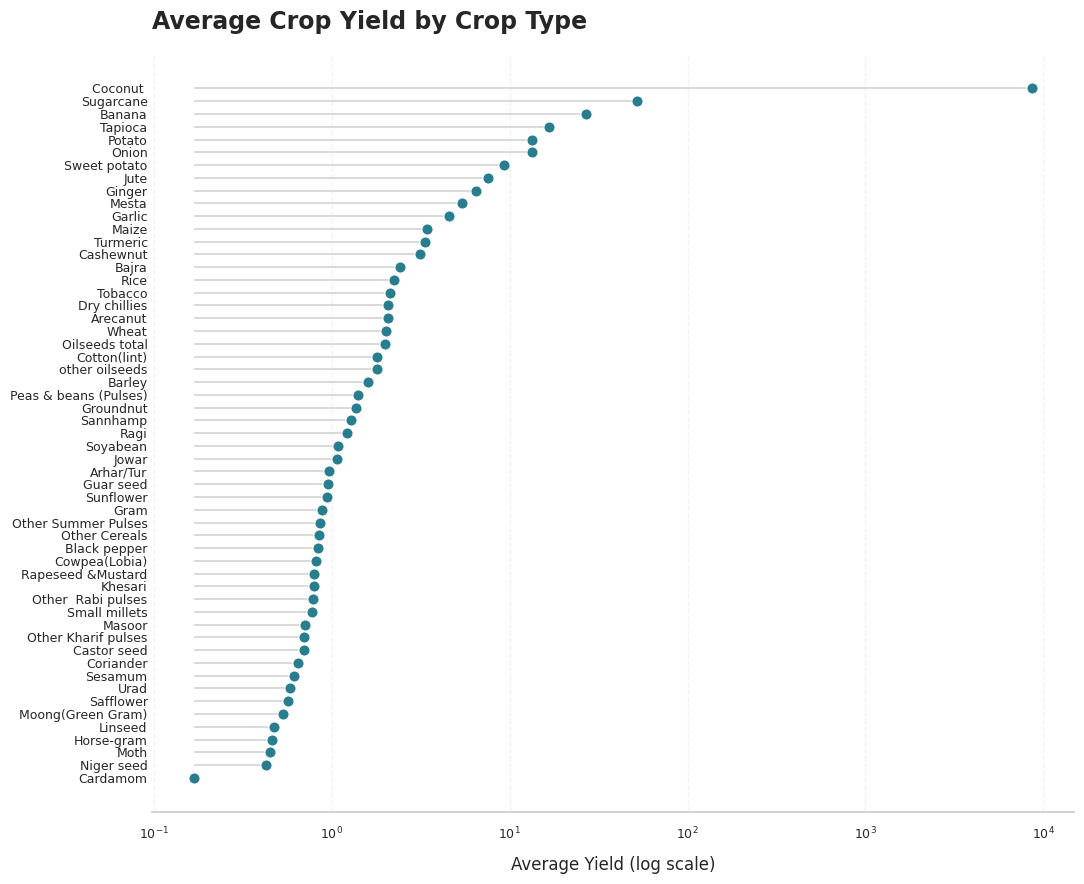

In [13]:

# 2. Average Crop Yield by Crop Type
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid", context="notebook")

avg_yield_crop = (
    df.groupby("Crop")["Yield"]
    .mean()
    .sort_values()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(11, 9))

y_pos = np.arange(len(avg_yield_crop))

ax.hlines(
    y=y_pos,
    xmin=avg_yield_crop["Yield"].min(),
    xmax=avg_yield_crop["Yield"],
    linewidth=1.2,
    color="lightgray"
)

ax.scatter(
    avg_yield_crop["Yield"],
    y_pos,
    s=65,
    color="#287D8E",
    edgecolor="white",
    linewidth=0.8,
    zorder=3
)

ax.set_xscale("log")
ax.set_yticks(y_pos)
ax.set_yticklabels(avg_yield_crop["Crop"])

ax.set_title(
    "Average Crop Yield by Crop Type",
    loc="left",
    fontsize=17,
    fontweight="bold",
    pad=18
)
ax.set_xlabel("Average Yield (log scale)", labelpad=10)
ax.set_ylabel("")

ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.grid(axis="y", visible=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.tick_params(axis="y", length=0, labelsize=9)
ax.tick_params(axis="x", labelsize=9)

plt.tight_layout()
plt.show()
plt.close("all")


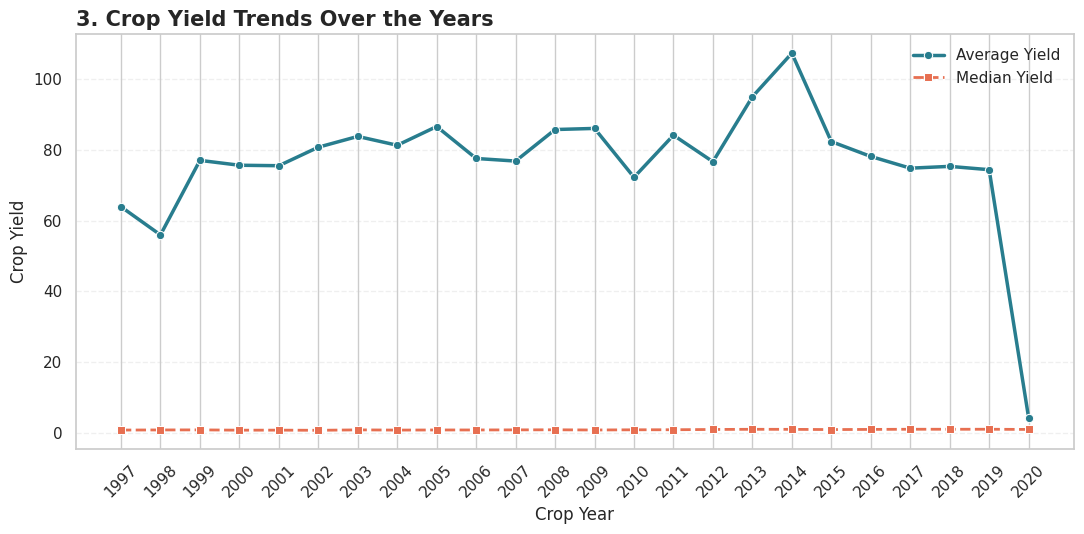

In [14]:
# 3. Crop Yield Trends Over the Years
import matplotlib.pyplot as plt
import seaborn as sns

yearly_yield = df.groupby("Crop_Year")["Yield"].agg(
    Average="mean",
    Median="median"
).reset_index()

plt.figure(figsize=(11, 5.5))
sns.set_theme(style="whitegrid")

sns.lineplot(
    data=yearly_yield, x="Crop_Year", y="Average",
    marker="o", linewidth=2.5, color="#287D8E",
    label="Average Yield"
)

sns.lineplot(
    data=yearly_yield, x="Crop_Year", y="Median",
    marker="s", linewidth=2, linestyle="--",
    color="#E76F51", label="Median Yield"
)

plt.title("3. Crop Yield Trends Over the Years",
          fontsize=15, fontweight="bold", loc="left")
plt.xlabel("Crop Year")
plt.ylabel("Crop Yield")
plt.xticks(sorted(yearly_yield["Crop_Year"].unique()), rotation=45)
plt.legend(frameon=False)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()
plt.close("all")

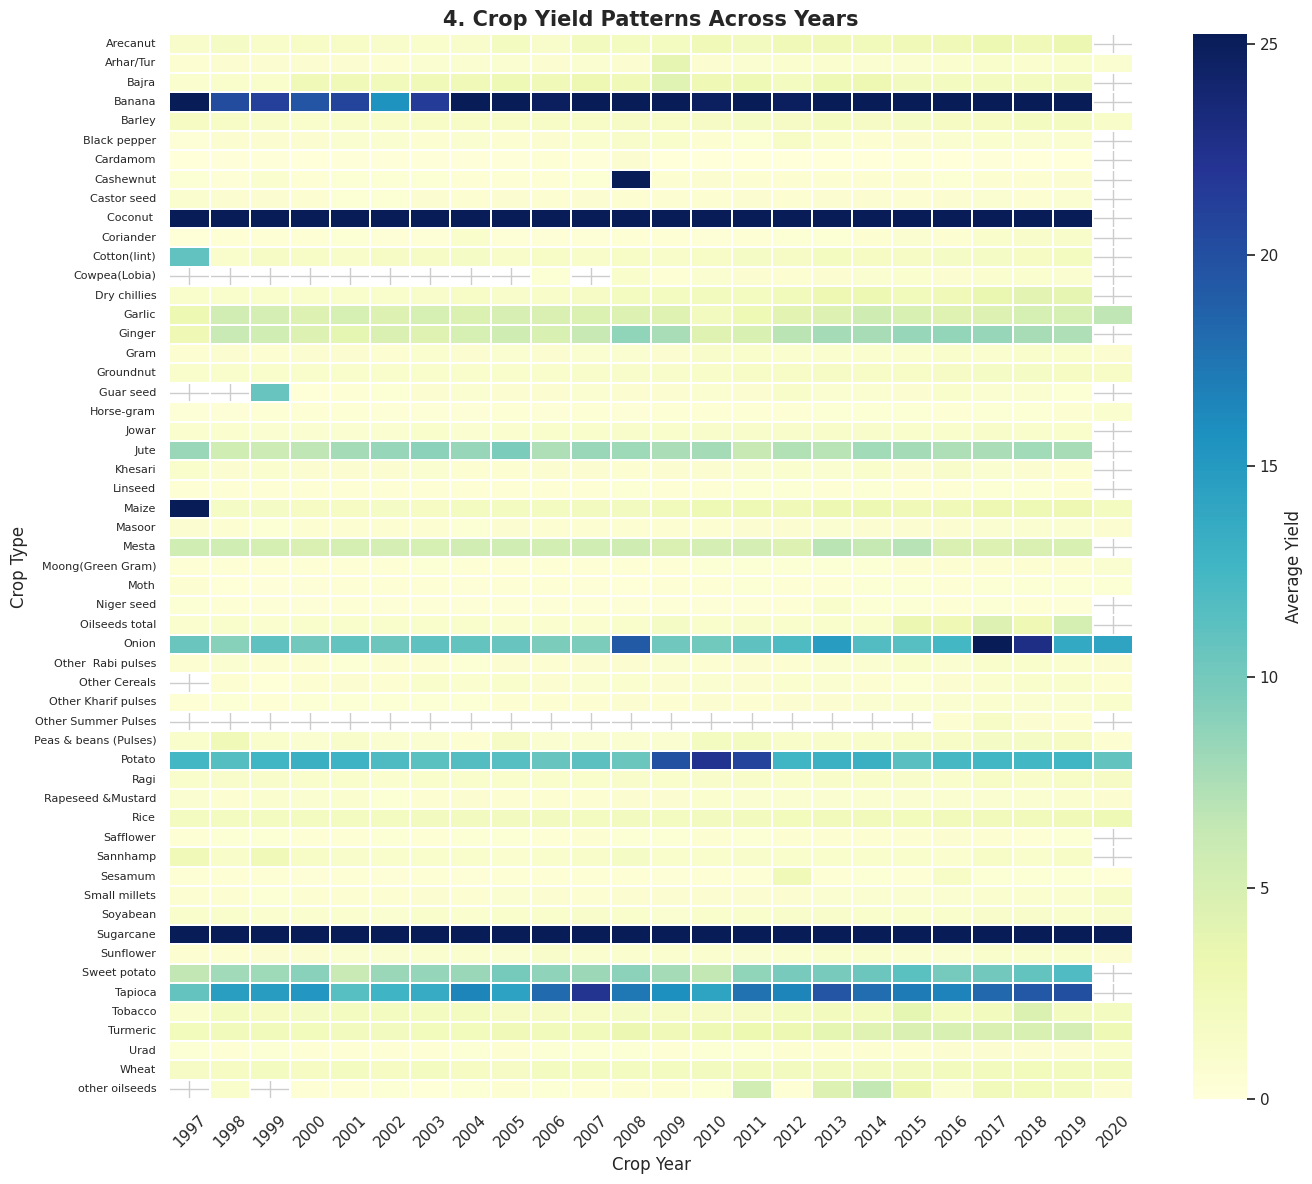

In [15]:
# 4. Crop Type × Year Heat-map
plt.figure(figsize=(14, 12))

pivot_crop_year = df.pivot_table(
    values='Yield', index='Crop',
    columns='Crop_Year', aggfunc='mean'
)

sns.heatmap(
    pivot_crop_year,
    cmap='YlGnBu',
    vmin=0,
    vmax=pivot_crop_year.stack().quantile(0.95),
    linewidths=0.2,
    mask=pivot_crop_year.isna(),
    yticklabels=True,
    cbar_kws={'label': 'Average Yield'}
)

plt.title('4. Crop Yield Patterns Across Years',
          fontsize=15, fontweight='bold')
plt.xlabel('Crop Year')
plt.ylabel('Crop Type')
plt.xticks(rotation=45)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()
plt.close('all')

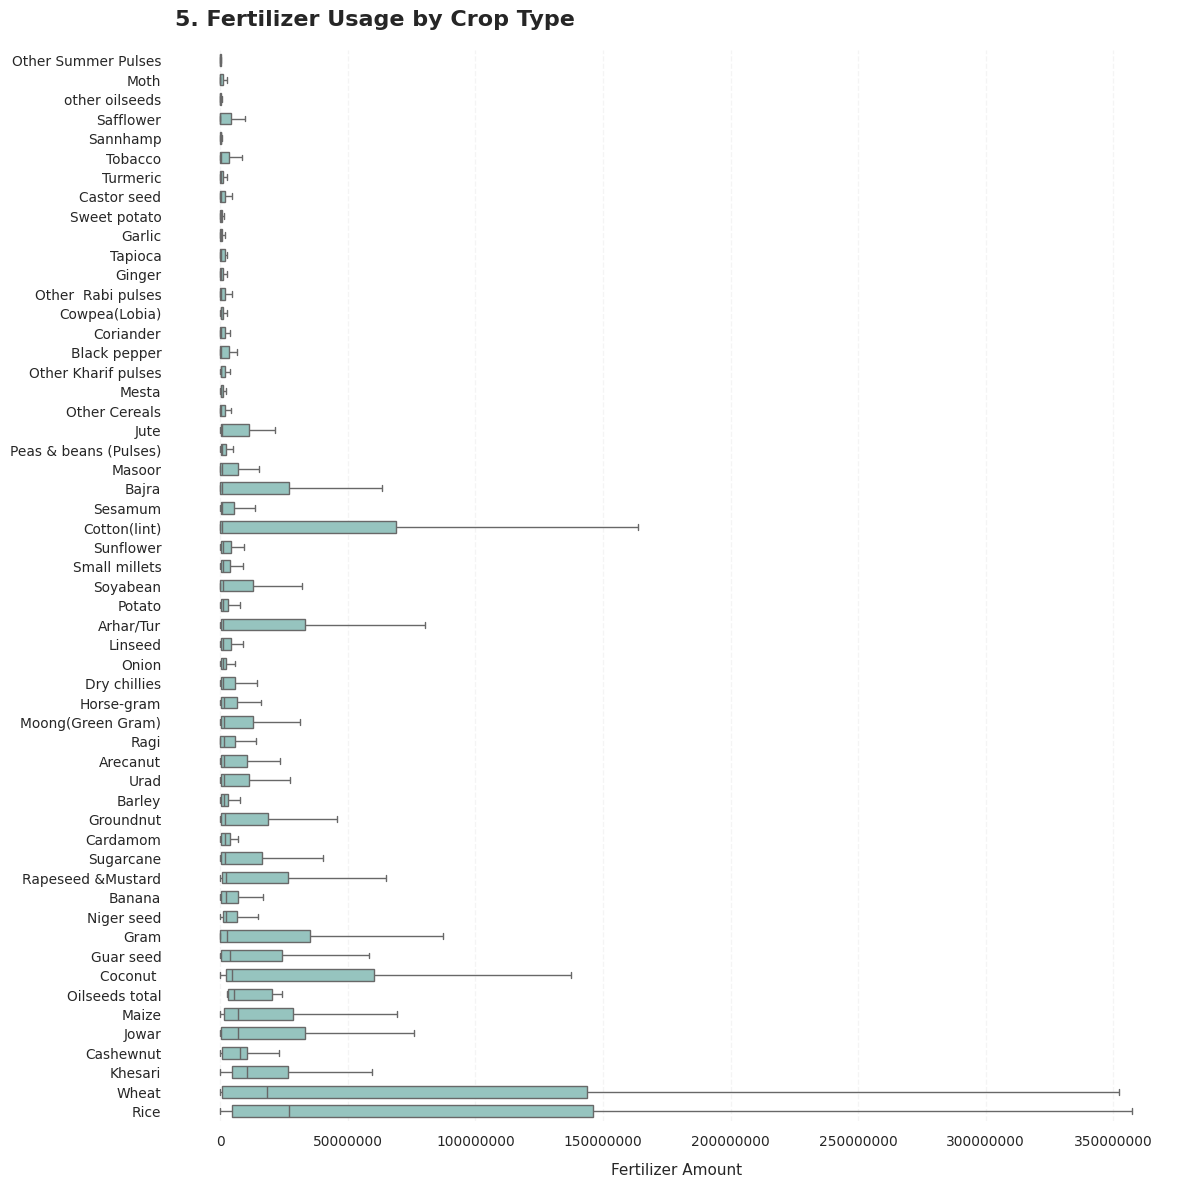

In [16]:
# 5. Fertilizer Usage by Crop Type
plt.figure(figsize=(12, 12))
sns.set_theme(style="whitegrid", font_scale=0.9)

crop_order = df.groupby('Crop')['Fertilizer'].median().sort_values().index

ax = sns.boxplot(
    data=df, y='Crop', x='Fertilizer',
    order=crop_order,
    color='#8ECCC5',
    showfliers=False,
    width=0.6,
    linewidth=1
)

ax.set_title('5. Fertilizer Usage by Crop Type',
             fontsize=16, fontweight='bold', loc='left', pad=18)
ax.set_xlabel('Fertilizer Amount', fontsize=11, labelpad=10)
ax.set_ylabel('')
ax.ticklabel_format(axis='x', style='plain', useOffset=False)
ax.grid(axis='x', linestyle='--', alpha=0.2)
ax.grid(axis='y', visible=False)
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()
plt.close('all')

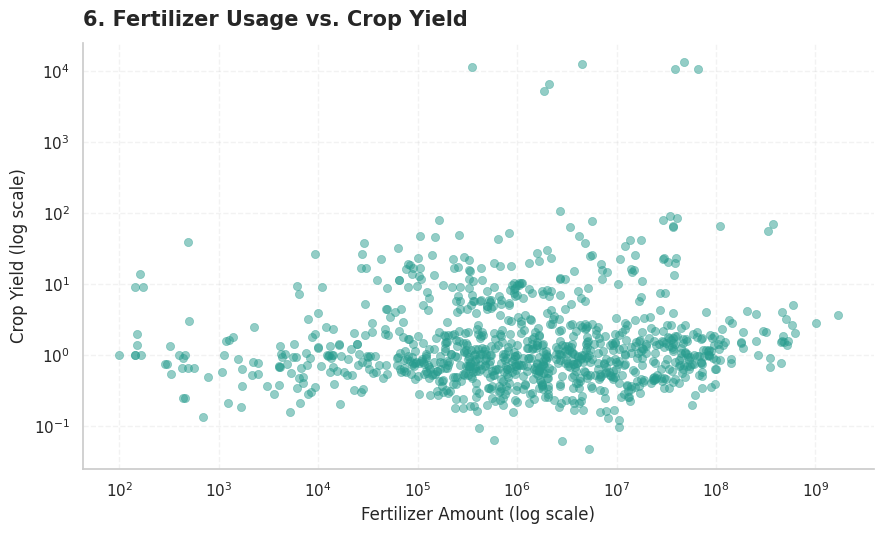

In [17]:
# 6. Fertilizer Usage vs. Crop Yield
sample = df.dropna(subset=['Fertilizer', 'Yield'])
sample = sample[
    (sample['Fertilizer'] > 0) & (sample['Yield'] > 0)
].sample(n=min(1000, len(sample)), random_state=42)

plt.figure(figsize=(9, 5.5))
sns.set_theme(style="whitegrid")

sns.scatterplot(
    data=sample, x='Fertilizer', y='Yield',
    color='#299D8F', alpha=0.5, s=35, edgecolor=None
)

plt.xscale('log')
plt.yscale('log')
plt.title('6. Fertilizer Usage vs. Crop Yield',
          fontsize=15, fontweight='bold', loc='left', pad=12)
plt.xlabel('Fertilizer Amount (log scale)')
plt.ylabel('Crop Yield (log scale)')
plt.grid(True, which='major', linestyle='--', alpha=0.25)
sns.despine()
plt.tight_layout()
plt.show()
plt.close('all')

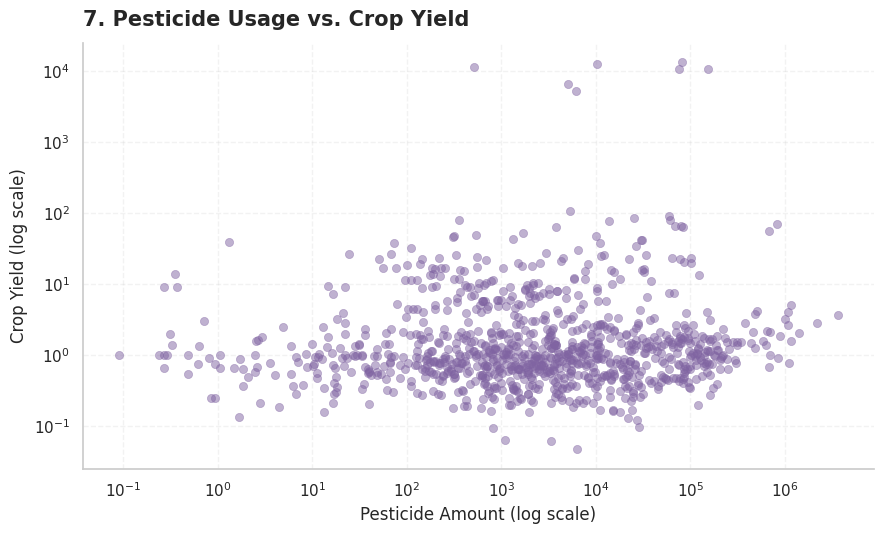

In [18]:
# 7. Pesticide Usage vs. Crop Yield
sample = df.dropna(subset=['Pesticide', 'Yield'])
sample = sample[
    (sample['Pesticide'] > 0) & (sample['Yield'] > 0)
].sample(n=min(1000, len(sample)), random_state=42)

plt.figure(figsize=(9, 5.5))
sns.set_theme(style="whitegrid")

sns.scatterplot(
    data=sample, x='Pesticide', y='Yield',
    color='#8064A2', alpha=0.5, s=35, edgecolor=None
)

plt.xscale('log')
plt.yscale('log')
plt.title('7. Pesticide Usage vs. Crop Yield',
          fontsize=15, fontweight='bold', loc='left', pad=12)
plt.xlabel('Pesticide Amount (log scale)')
plt.ylabel('Crop Yield (log scale)')
plt.grid(True, which='major', linestyle='--', alpha=0.25)
sns.despine()
plt.tight_layout()
plt.show()
plt.close('all')

/tmp/ipykernel_28145/904251911.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rain_order = df.groupby('Rain_Category')['Yield'].mean().sort_values().index


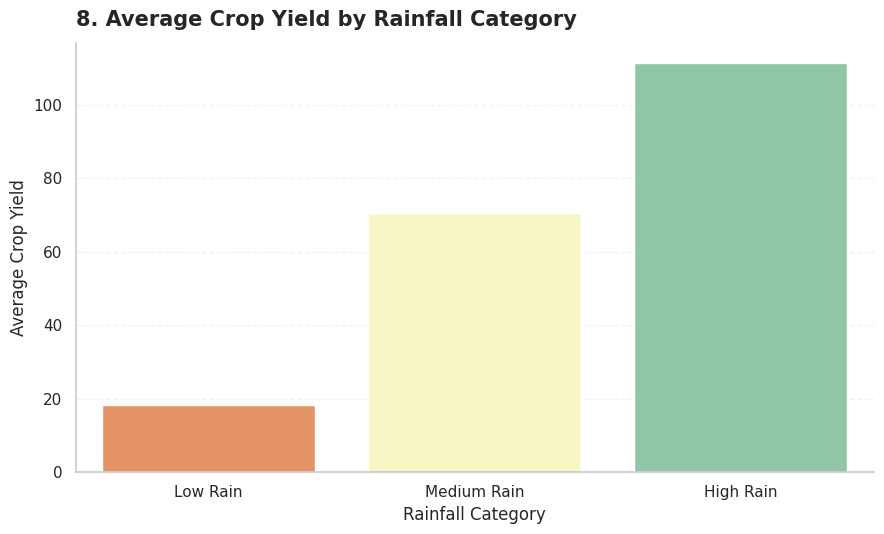

In [19]:
# 8. Rainfall Category vs. Crop Yield
plt.figure(figsize=(9, 5.5))
sns.set_theme(style="whitegrid")

rain_order = df.groupby('Rain_Category')['Yield'].mean().sort_values().index

sns.barplot(
    data=df, x='Rain_Category', y='Yield',
    order=rain_order, hue='Rain_Category',
    palette='Spectral', legend=False, errorbar=None
)

plt.title('8. Average Crop Yield by Rainfall Category',
          fontsize=15, fontweight='bold', loc='left', pad=12)
plt.xlabel('Rainfall Category')
plt.ylabel('Average Crop Yield')
plt.grid(axis='y', linestyle='--', alpha=0.25)
sns.despine()
plt.tight_layout()
plt.show()
plt.close('all')

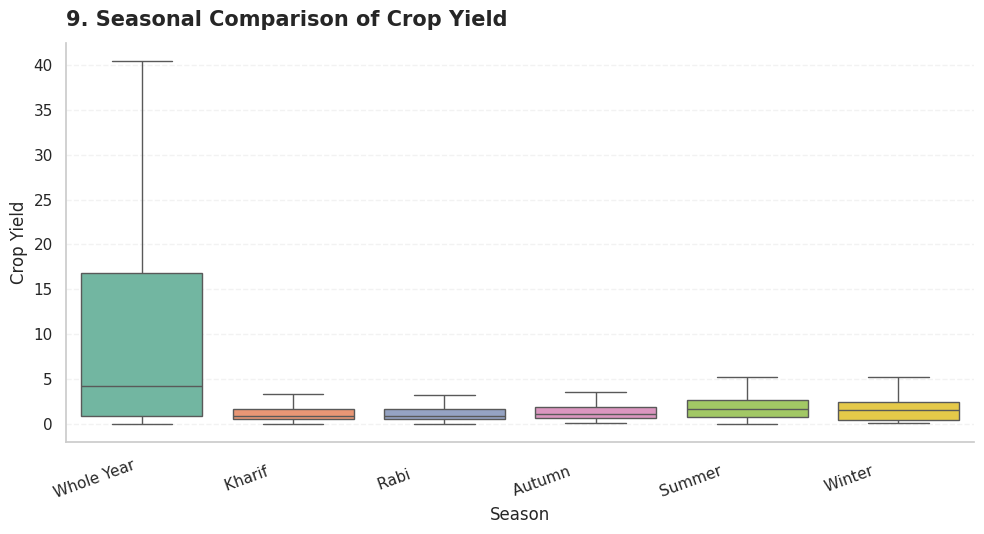

In [20]:
# 9. Seasonal Comparison of Crop Yield
plt.figure(figsize=(10, 5.5))
sns.set_theme(style="whitegrid")

sns.boxplot(
    data=df, x='Season', y='Yield',
    hue='Season', palette='Set2',
    legend=False, showfliers=False
)

plt.title('9. Seasonal Comparison of Crop Yield',
          fontsize=15, fontweight='bold', loc='left', pad=12)
plt.xlabel('Season')
plt.ylabel('Crop Yield')
plt.xticks(rotation=20, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.25)
sns.despine()
plt.tight_layout()
plt.show()
plt.close('all')

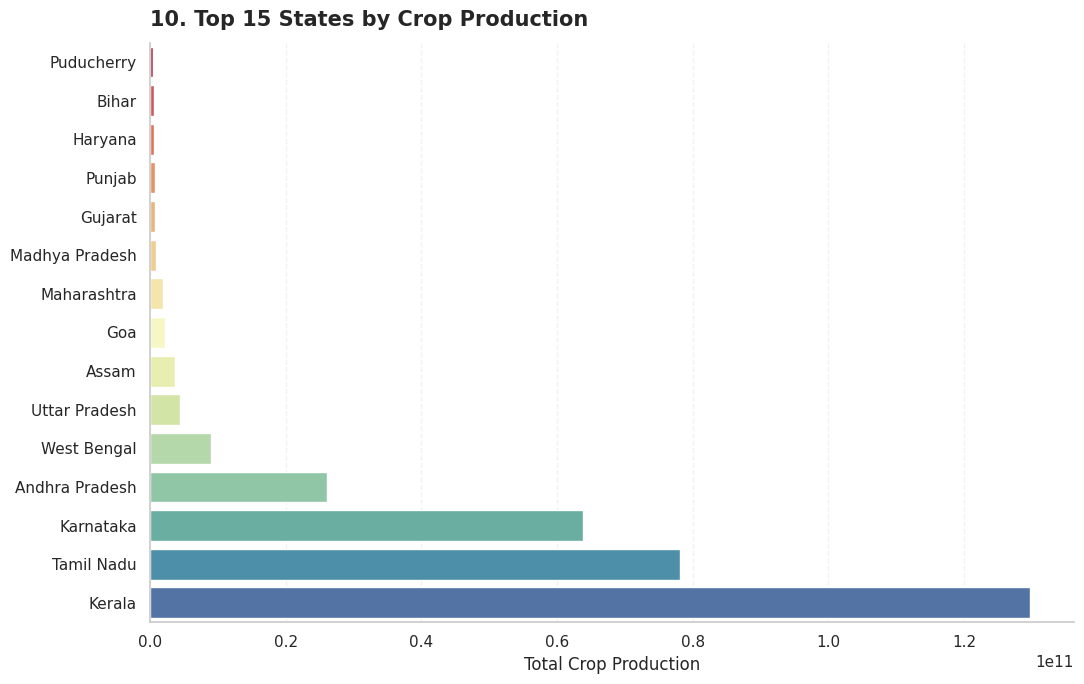

In [21]:
# 10. Crop Production by State
plt.figure(figsize=(11, 7))
sns.set_theme(style="whitegrid")

state_prod = (
    df.groupby('State')['Production'].sum()
    .nlargest(15).sort_values(ascending=True)
    .reset_index()
)

sns.barplot(
    data=state_prod, x='Production', y='State',
    hue='State', palette='Spectral', legend=False
)

plt.title('10. Top 15 States by Crop Production',
          fontsize=15, fontweight='bold', loc='left', pad=12)
plt.xlabel('Total Crop Production')
plt.ylabel('')
plt.grid(axis='x', linestyle='--', alpha=0.25)
sns.despine()
plt.tight_layout()
plt.show()
plt.close('all')

### Part 2: Advanced Visualization and Analysis (Plots 11 to 20)

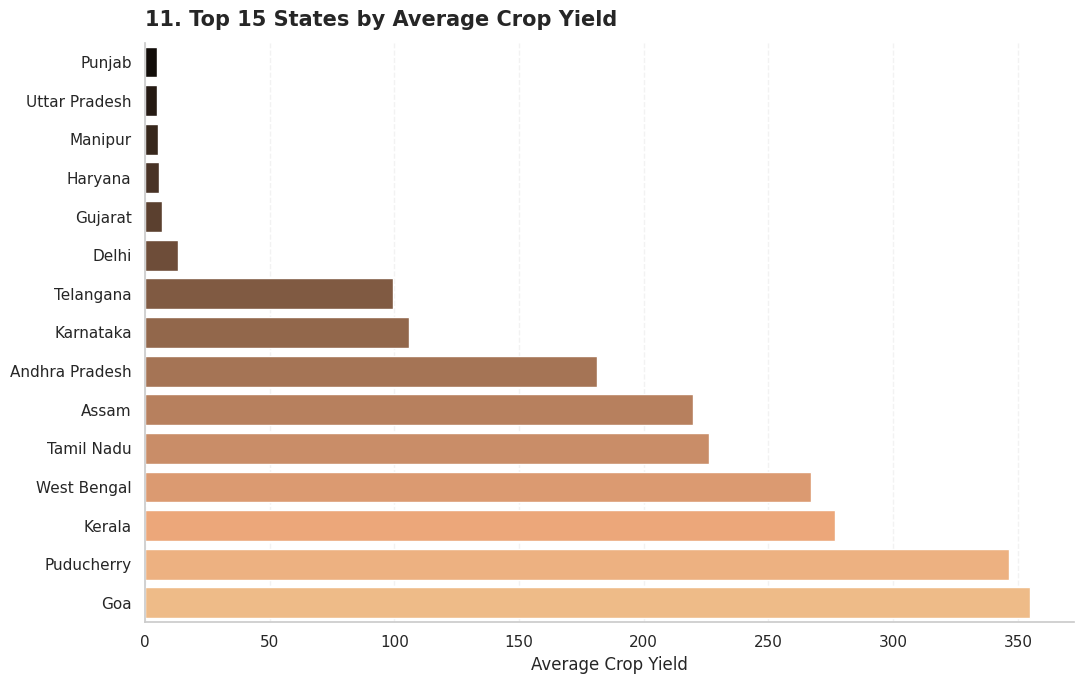

In [22]:
# 11. Crop Yield by State
plt.figure(figsize=(11, 7))
sns.set_theme(style="whitegrid")

state_yield = (
    df.groupby('State')['Yield'].mean()
    .nlargest(15).sort_values(ascending=True)
    .reset_index()
)

sns.barplot(
    data=state_yield, x='Yield', y='State',
    hue='State', palette='copper', legend=False
)

plt.title('11. Top 15 States by Average Crop Yield',
          fontsize=15, fontweight='bold', loc='left', pad=12)
plt.xlabel('Average Crop Yield')
plt.ylabel('')
plt.grid(axis='x', linestyle='--', alpha=0.25)
sns.despine()
plt.tight_layout()
plt.show()
plt.close('all')

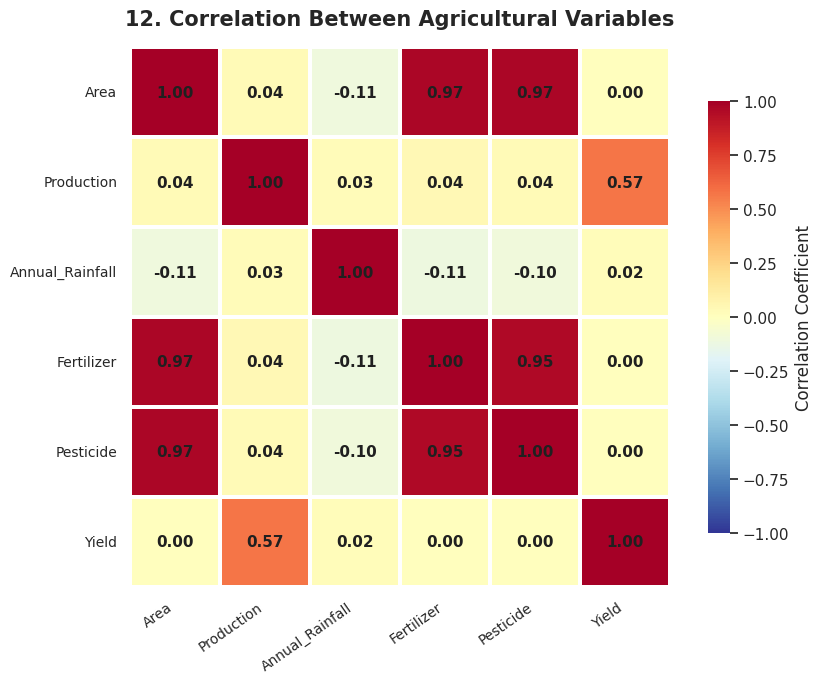

In [23]:
# 12. Correlation Heat-map of Agricultural Variables
plt.figure(figsize=(9, 7))
sns.set_theme(style="white")

corr_matrix = df[
    ['Area', 'Production', 'Annual_Rainfall',
     'Fertilizer', 'Pesticide', 'Yield']
].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='RdYlBu_r',
    fmt='.2f',
    vmin=-1, vmax=1, center=0,
    square=True,
    linewidths=1.5,
    linecolor='white',
    annot_kws={'size': 11, 'weight': 'bold', 'color': '#202020'},
    cbar_kws={'label': 'Correlation Coefficient', 'shrink': 0.8}
)

plt.title(
    '12. Correlation Between Agricultural Variables',
    fontsize=15, fontweight='bold', pad=16
)
plt.xticks(rotation=35, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()
plt.close('all')

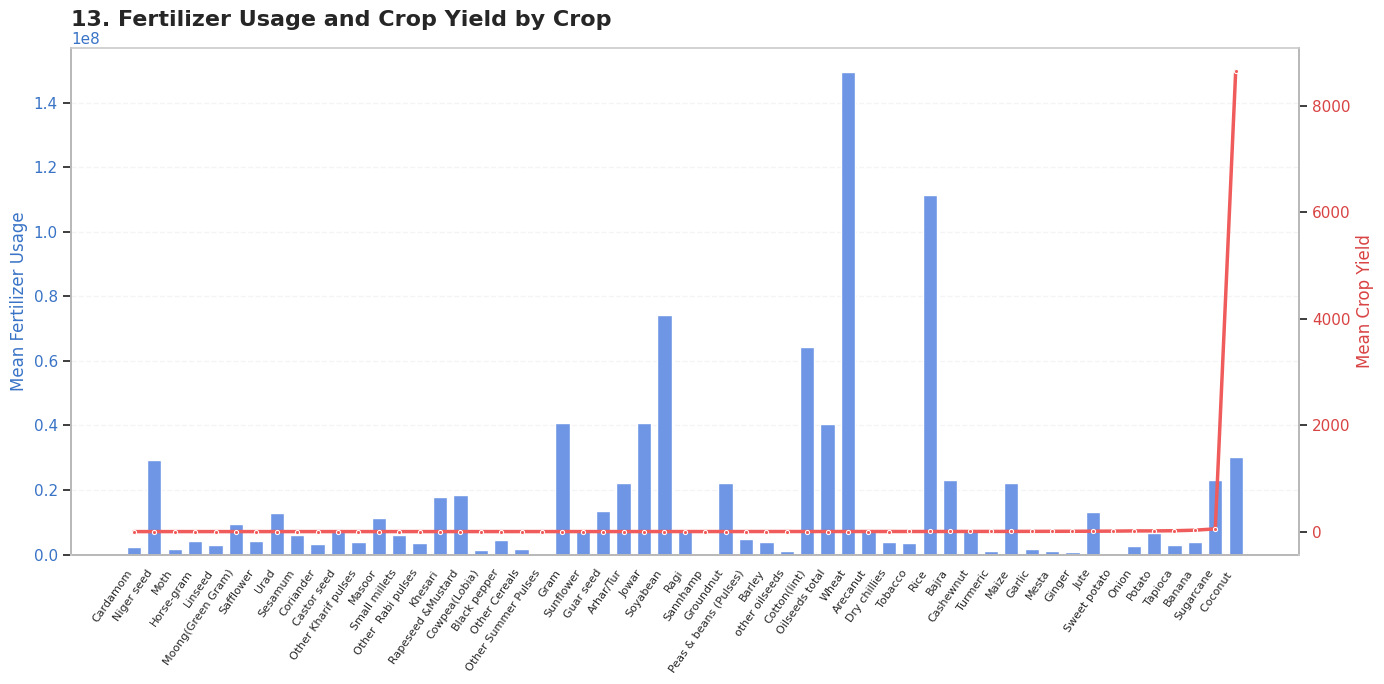

In [24]:
# 13. Fertilizer Usage and Yield by Crop Type
fig, ax1 = plt.subplots(figsize=(14, 7))
sns.set_theme(style="whitegrid")

crop_grouped = df.groupby('Crop')[['Fertilizer', 'Yield']].mean()
crop_grouped = crop_grouped.sort_values('Yield').reset_index()

sns.barplot(
    data=crop_grouped, x='Crop', y='Fertilizer',
    color='#5B8FF9', ax=ax1, width=0.7
)

ax1.set_ylabel('Mean Fertilizer Usage', color='#3973C6')
ax1.set_xlabel('')
ax1.tick_params(axis='y', labelcolor='#3973C6')
ax1.set_xticks(range(len(crop_grouped)))
ax1.set_xticklabels(crop_grouped['Crop'], rotation=55, ha='right', fontsize=8)

ax2 = ax1.twinx()
sns.lineplot(
    x=range(len(crop_grouped)), y=crop_grouped['Yield'],
    color='#F05B5B', marker='o', markersize=3,
    linewidth=2.5, ax=ax2
)

ax2.set_ylabel('Mean Crop Yield', color='#D94343')
ax2.tick_params(axis='y', labelcolor='#D94343')
ax2.grid(False)

ax1.set_title(
    '13. Fertilizer Usage and Crop Yield by Crop',
    fontsize=16, fontweight='bold', loc='left', pad=16
)

ax1.grid(axis='y', linestyle='--', alpha=0.2)
sns.despine(ax=ax1, right=False)
plt.tight_layout()
plt.show()
plt.close('all')

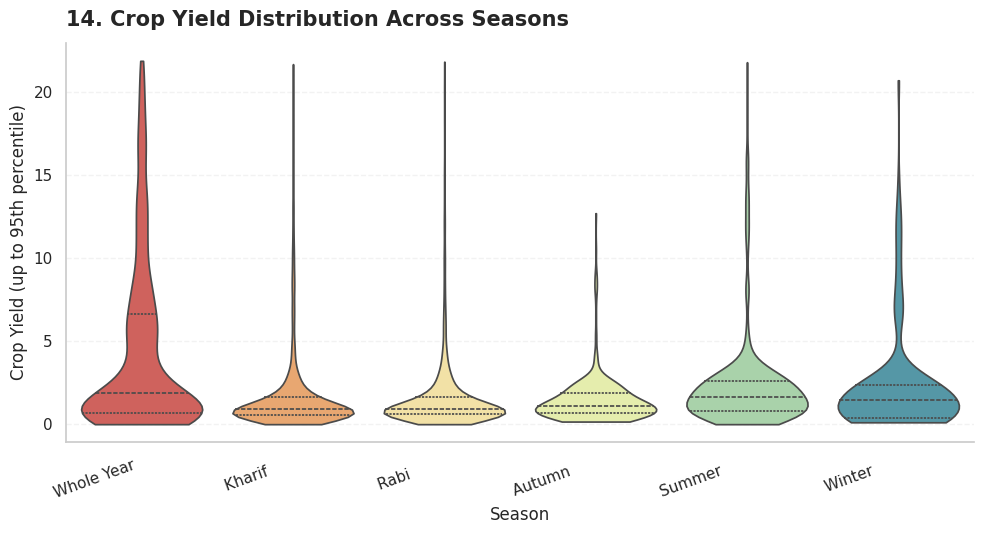

In [25]:
# 14. Crop Yield Distribution Across Seasons
plt.figure(figsize=(10, 5.5))
sns.set_theme(style="whitegrid")

yield_limit = df['Yield'].quantile(0.95)
plot_df = df[df['Yield'] <= yield_limit]

sns.violinplot(
    data=plot_df, x='Season', y='Yield',
    hue='Season', palette='Spectral',
    legend=False, inner='quartile', cut=0
)

plt.title('14. Crop Yield Distribution Across Seasons',
          fontsize=15, fontweight='bold', loc='left', pad=12)
plt.xlabel('Season')
plt.ylabel('Crop Yield (up to 95th percentile)')
plt.xticks(rotation=20, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.25)
sns.despine()
plt.tight_layout()
plt.show()
plt.close('all')

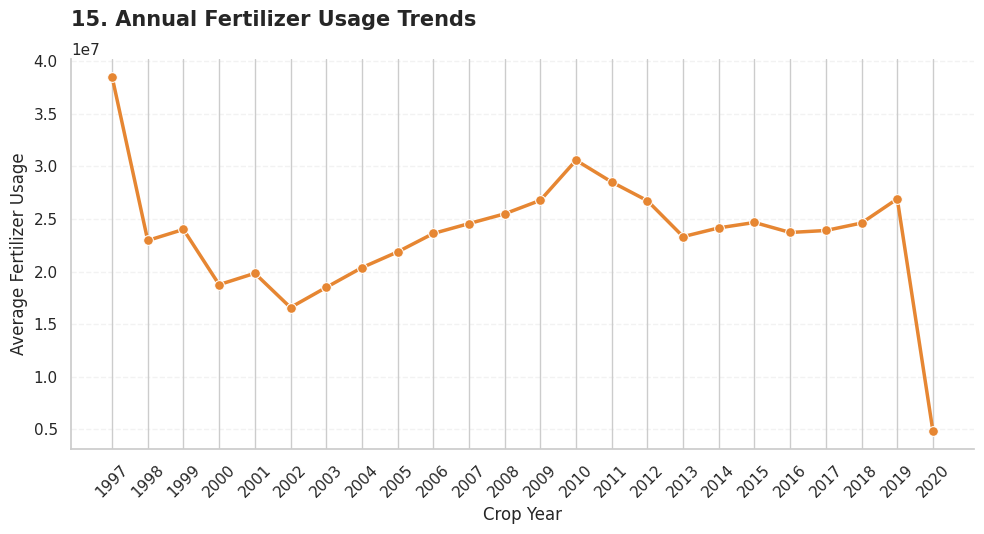

In [26]:
# 15. Annual Fertilizer Usage Trends
plt.figure(figsize=(10, 5.5))
sns.set_theme(style="whitegrid")

yearly_fertilizer = df.groupby('Crop_Year')['Fertilizer'].mean().reset_index()

sns.lineplot(
    data=yearly_fertilizer,
    x='Crop_Year', y='Fertilizer',
    marker='o', markersize=7,
    linewidth=2.5, color='#E68632'
)

plt.title('15. Annual Fertilizer Usage Trends',
          fontsize=15, fontweight='bold', loc='left', pad=12)
plt.xlabel('Crop Year')
plt.ylabel('Average Fertilizer Usage')
plt.xticks(sorted(yearly_fertilizer['Crop_Year'].unique()), rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.25)
sns.despine()
plt.tight_layout()
plt.show()
plt.close('all')

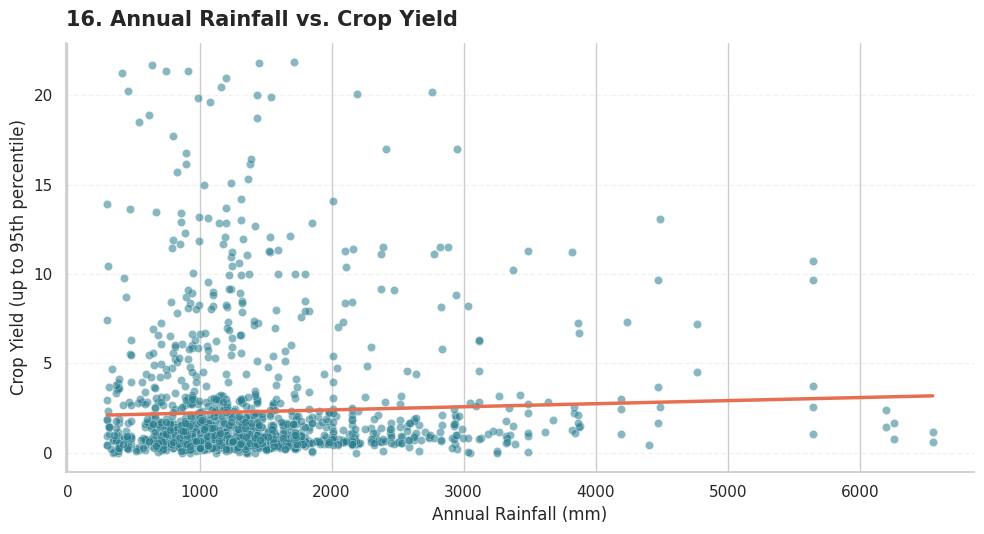

In [27]:
# 16. Rainfall vs. Crop Yield
plt.figure(figsize=(10, 5.5))
sns.set_theme(style="whitegrid")

plot_df = df.dropna(subset=['Annual_Rainfall', 'Yield'])
plot_df = plot_df[plot_df['Yield'] <= plot_df['Yield'].quantile(0.95)]
plot_df = plot_df.sample(n=min(1500, len(plot_df)), random_state=42)

sns.scatterplot(
    data=plot_df, x='Annual_Rainfall', y='Yield',
    color='#287D8E', alpha=0.55, s=35,
    edgecolor='white', linewidth=0.3
)

sns.regplot(
    data=plot_df, x='Annual_Rainfall', y='Yield',
    scatter=False, color='#E76F51', ci=None,
    line_kws={'linewidth': 2.5}
)

plt.title('16. Annual Rainfall vs. Crop Yield',
          fontsize=15, fontweight='bold', loc='left', pad=12)
plt.xlabel('Annual Rainfall (mm)')
plt.ylabel('Crop Yield (up to 95th percentile)')
plt.grid(axis='y', linestyle='--', alpha=0.25)
sns.despine()
plt.tight_layout()
plt.show()
plt.close('all')

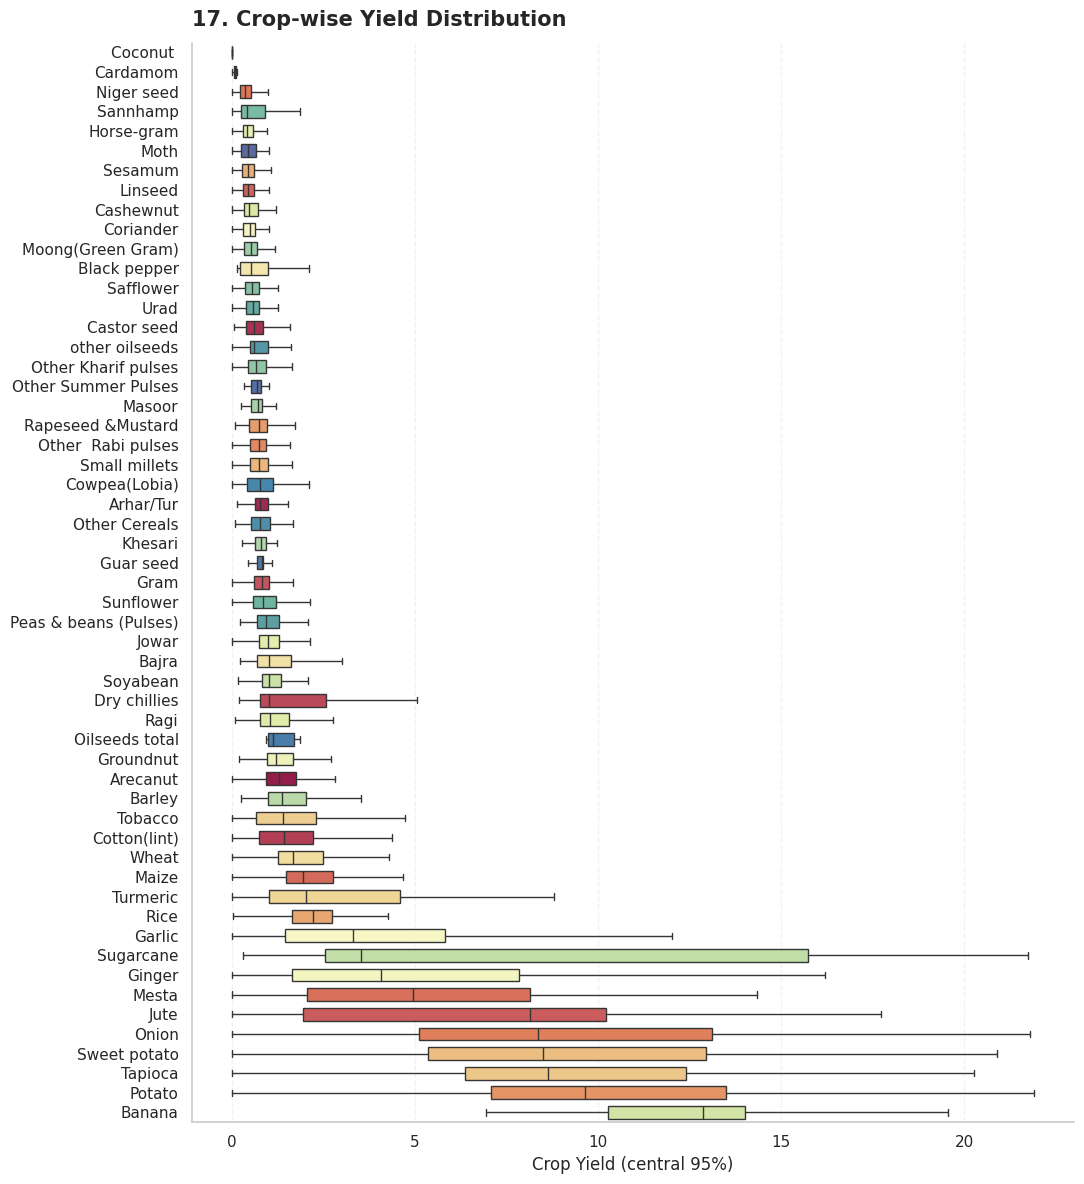

In [28]:
# 17. Crop-wise Yield Distribution
plt.figure(figsize=(11, 12))
sns.set_theme(style="whitegrid")

plot_df = df[df['Yield'] <= df['Yield'].quantile(0.95)]
crop_order = plot_df.groupby('Crop')['Yield'].median().sort_values().index

sns.boxplot(
    data=plot_df, y='Crop', x='Yield',
    order=crop_order, hue='Crop',
    palette='Spectral', legend=False,
    showfliers=False, width=0.65
)

plt.title('17. Crop-wise Yield Distribution',
          fontsize=15, fontweight='bold', loc='left', pad=12)
plt.xlabel('Crop Yield (central 95%)')
plt.ylabel('')
plt.grid(axis='x', linestyle='--', alpha=0.25)
sns.despine()
plt.tight_layout()
plt.show()
plt.close('all')

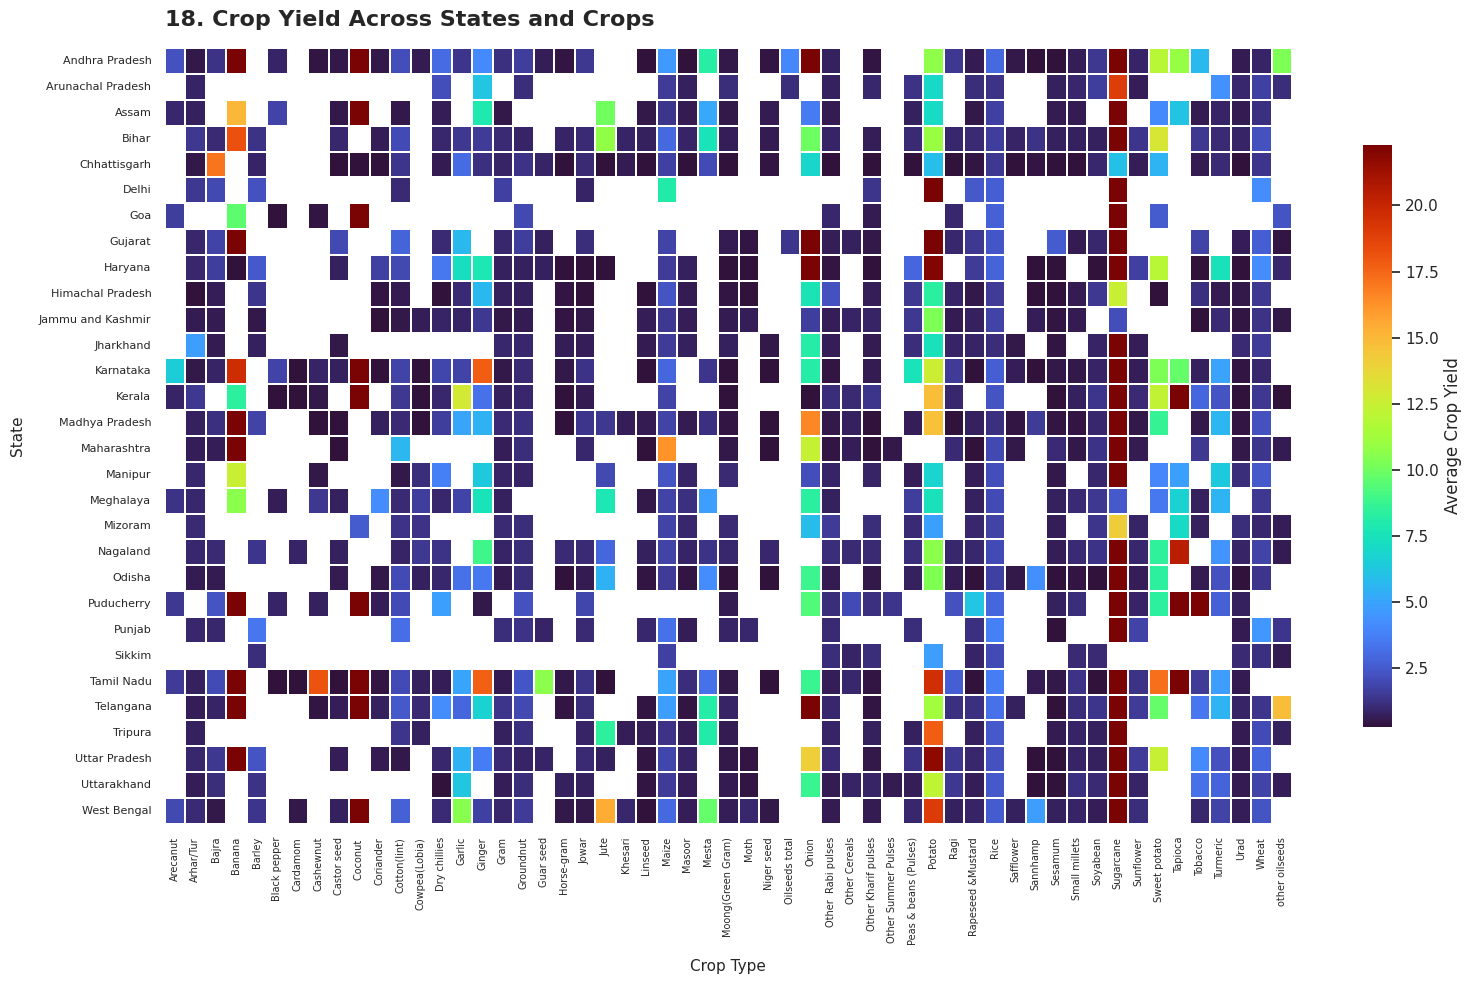

In [29]:
# 18. State × Crop Yield Heat-map
plt.figure(figsize=(16, 10))
sns.set_theme(style="white")

pivot_state_crop = df.pivot_table(
    values='Yield', index='State',
    columns='Crop', aggfunc='mean'
)

sns.heatmap(
    pivot_state_crop,
    cmap='turbo',
    vmin=pivot_state_crop.stack().quantile(0.05),
    vmax=pivot_state_crop.stack().quantile(0.95),
    linewidths=0.2,
    linecolor='white',
    mask=pivot_state_crop.isna(),
    cbar_kws={'label': 'Average Crop Yield', 'shrink': 0.75}
)

plt.title('18. Crop Yield Across States and Crops',
          fontsize=16, fontweight='bold', loc='left', pad=16)
plt.xlabel('Crop Type', fontsize=11, labelpad=10)
plt.ylabel('State', fontsize=11, labelpad=10)
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()
plt.close('all')

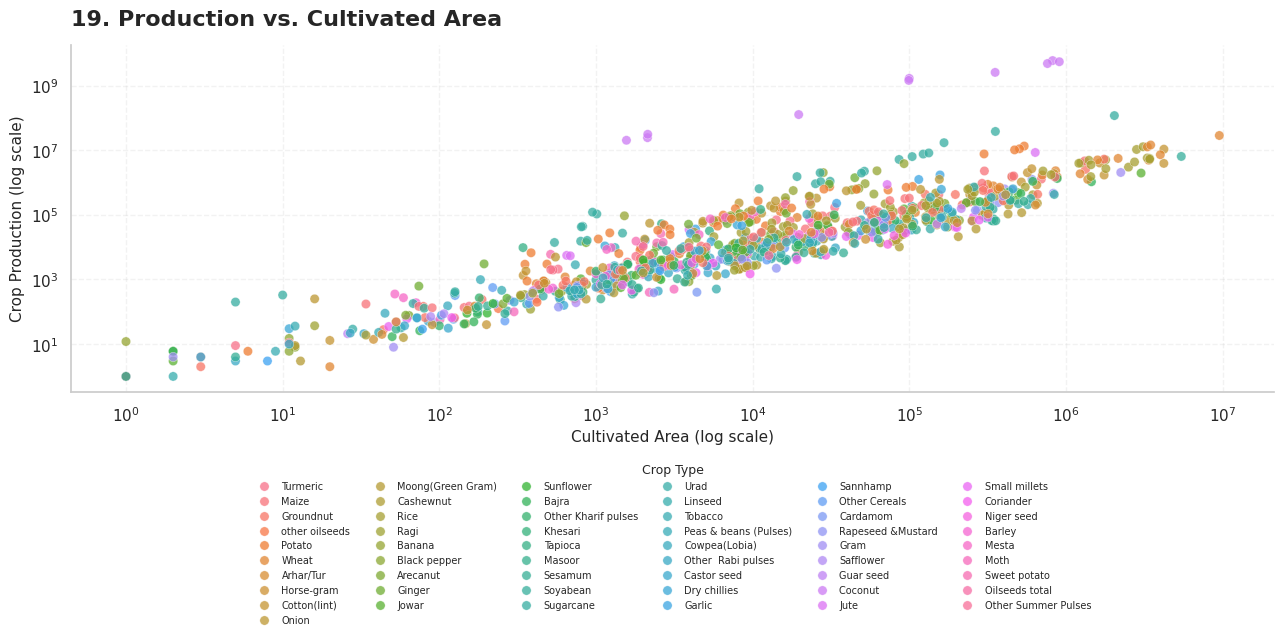

In [30]:
# 19. Production vs. Cultivated Area
plt.figure(figsize=(13, 8))
sns.set_theme(style="whitegrid")

sample = df.dropna(subset=['Area', 'Production', 'Crop'])
sample = sample[(sample['Area'] > 0) & (sample['Production'] > 0)]
sample = sample.sample(n=min(1000, len(sample)), random_state=42)

ax = sns.scatterplot(
    data=sample, x='Area', y='Production',
    hue='Crop', palette='husl',
    alpha=0.75, s=45, edgecolor='white', linewidth=0.3,
    legend='full'
)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title('19. Production vs. Cultivated Area',
             fontsize=16, fontweight='bold', loc='left', pad=14)
ax.set_xlabel('Cultivated Area (log scale)', fontsize=11)
ax.set_ylabel('Crop Production (log scale)', fontsize=11)
ax.grid(True, which='major', linestyle='--', alpha=0.25)

ax.legend(
    title='Crop Type', bbox_to_anchor=(0.5, -0.18),
    loc='upper center', ncol=6, fontsize=7,
    title_fontsize=9, frameon=False
)

sns.despine()
plt.tight_layout(rect=[0, 0.12, 1, 1])
plt.show()
plt.close('all')

In [31]:
# 20. Interactive Crop Productivity Dashboard
import ipywidgets as widgets
from ipywidgets import interact
from matplotlib.ticker import FuncFormatter

def update_dashboard(selected_crop):
    crop_df = df[df['Crop'] == selected_crop].dropna(
        subset=['Crop_Year', 'Yield', 'Fertilizer']
    )

    yearly_yield = crop_df.groupby('Crop_Year')['Yield'].mean().reset_index()

    fertilizer_limit = crop_df['Fertilizer'].quantile(0.95)
    plot_df = crop_df[crop_df['Fertilizer'] <= fertilizer_limit]

    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

    # Plot 1: Annual Yield Trend
    sns.lineplot(
        data=yearly_yield,
        x='Crop_Year', y='Yield',
        marker='o', markersize=6,
        linewidth=2.5, color='#287D8E',
        ax=axes[0]
    )

    axes[0].set_title('Annual Yield Trend', fontsize=13, fontweight='bold', pad=12)
    axes[0].set_xlabel('Crop Year')
    axes[0].set_ylabel('Average Crop Yield')
    axes[0].grid(axis='y', linestyle='--', alpha=0.25)

    # Plot 2: Fertilizer Usage vs. Yield
    sns.scatterplot(
        data=plot_df,
        x='Fertilizer', y='Yield',
        color='#E76F51', alpha=0.65, s=45,
        edgecolor='white', linewidth=0.4,
        ax=axes[1]
    )

    axes[1].set_xlim(left=0, right=fertilizer_limit)
    axes[1].xaxis.set_major_formatter(
        FuncFormatter(lambda x, _: f'{x:,.0f}')
    )
    axes[1].set_title('Fertilizer Usage vs. Yield', fontsize=13, fontweight='bold', pad=12)
    axes[1].set_xlabel('Fertilizer Amount (central 95%)')
    axes[1].set_ylabel('Crop Yield')
    axes[1].grid(axis='y', linestyle='--', alpha=0.25)

    for ax in axes:
        sns.despine(ax=ax)

    fig.suptitle(
        f'Crop Productivity Dashboard | {selected_crop}',
        fontsize=16, fontweight='bold', x=0.05, ha='left'
    )

    plt.tight_layout(rect=[0, 0, 1, 0.92])
    plt.show()
    plt.close('all')


crop_list = sorted(df['Crop'].dropna().unique())

interact(
    update_dashboard,
    selected_crop=widgets.Dropdown(
        options=crop_list,
        description='Select Crop:',
        style={'description_width': 'initial'}
    )
)

interactive(children=(Dropdown(description='Select Crop:', options=('Arecanut', 'Arhar/Tur', 'Bajra', 'Banana'…

<function __main__.update_dashboard(selected_crop)>

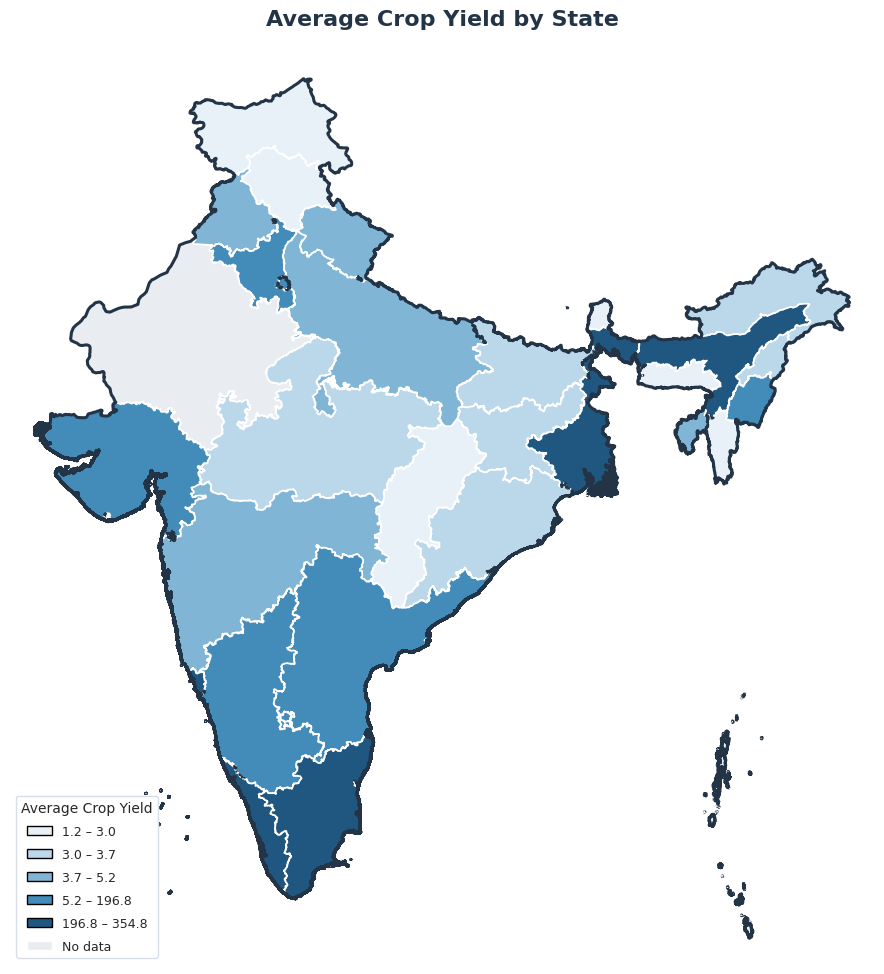

In [50]:

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(9, 10), facecolor="white")
ax.set_facecolor("white")

categories = pd.qcut(
    merged["Average_Yield"], q=5, duplicates="drop"
)

palette = ["#E8F1F8", "#BBD7EA", "#80B5D5", "#438BB9", "#205780"]

merged.plot(
    color="#E9EDF2",
    edgecolor="white",
    linewidth=1.2,
    ax=ax
)

for i, interval in enumerate(categories.cat.categories):
    merged.loc[categories == interval].plot(
        ax=ax,
        color=palette[i],
        edgecolor="white",
        linewidth=1.2
    )

merged.dissolve().boundary.plot(
    ax=ax,
    color="#243447",
    linewidth=2.2,
    zorder=5
)

legend_items = [
    Patch(
        facecolor=palette[i],
        edgecolor="black",
        label=f"{interval.left:,.1f} – {interval.right:,.1f}"
    )
    for i, interval in enumerate(categories.cat.categories)
]

if merged["Average_Yield"].isna().any():
    legend_items.append(
        Patch(facecolor="#E9EDF2", label="No data")
    )

ax.legend(
    handles=legend_items,
    title="Average Crop Yield",
    loc="lower left",
    frameon=True,
    facecolor="white",
    edgecolor="#D8DEE8",
    framealpha=1,
    fontsize=9,
    title_fontsize=10,
    labelspacing=0.8
)

ax.set_title(
    "Average Crop Yield by State",
    fontsize=16,
    fontweight="bold",
    color="#243447",
    pad=20
)

ax.axis("off")
ax.margins(0.03)
plt.tight_layout()
plt.show()


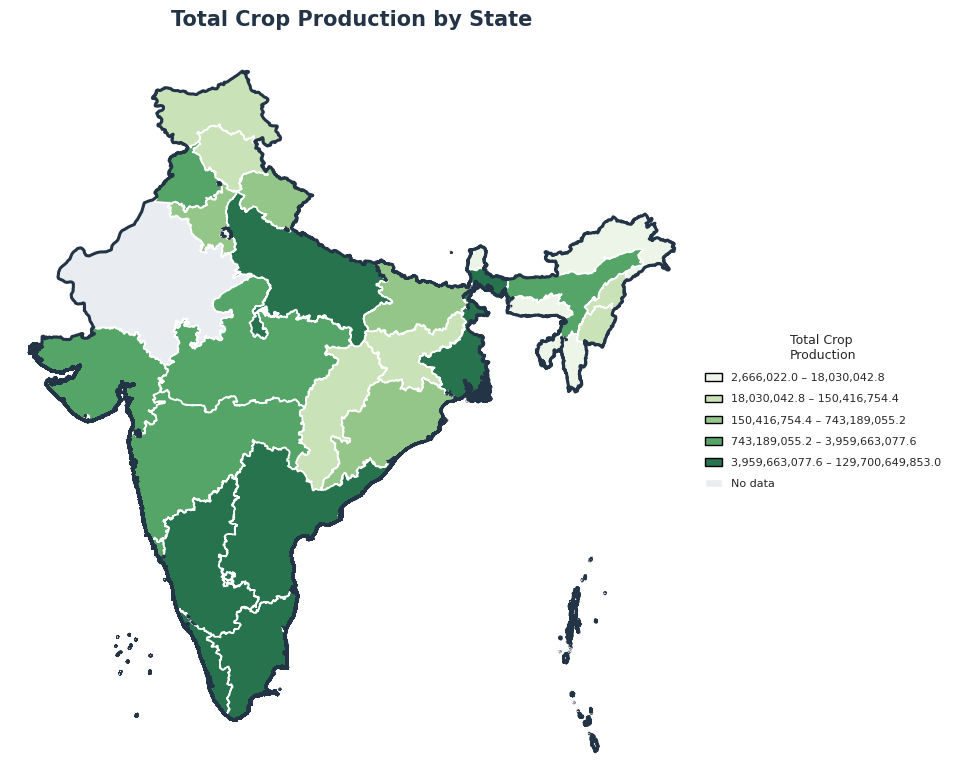

In [49]:

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(9, 10), facecolor="white")
ax.set_facecolor("white")

categories = pd.qcut(
    merged_prod["Total_Production"], q=5, duplicates="drop"
)

palette = ["#EDF5E8", "#C9E2B8", "#94C68A", "#55A568", "#26734D"]

merged_prod.plot(
    color="#E9EDF2",
    edgecolor="white",
    linewidth=1.2,
    ax=ax
)

for i, interval in enumerate(categories.cat.categories):
    merged_prod.loc[categories == interval].plot(
        ax=ax,
        color=palette[i],
        edgecolor="white",
        linewidth=1.2
    )

merged_prod.dissolve().boundary.plot(
    ax=ax,
    color="#243447",
    linewidth=2.2,
    zorder=5
)

legend_items = [
    Patch(
        facecolor=palette[i],
        edgecolor="black",
        label=f"{interval.left:,.1f} – {interval.right:,.1f}"
    )
    for i, interval in enumerate(categories.cat.categories)
]

if merged_prod["Total_Production"].isna().any():
    legend_items.append(
        Patch(facecolor="#E9EDF2", label="No data")
    )

# Move legend outside the map
ax.legend(
    handles=legend_items,
    title="Total Crop\nProduction",
    loc="center left",
    bbox_to_anchor=(1.01, 0.5),
    frameon=False,
    fontsize=8,
    title_fontsize=9,
    labelspacing=1.0,
    handlelength=1.5,
    borderaxespad=0
)

ax.set_title(
    "Total Crop Production by State",
    fontsize=15,
    fontweight="bold",
    color="#243447",
    pad=18
)

ax.axis("off")
ax.margins(0.03)

plt.subplots_adjust(left=0.02, right=0.78, top=0.92, bottom=0.03)
plt.show()


```markdown
# Comprehensive Crop Yield Analysis Project

This project applies computational techniques across five distinct stages mapped directly to our curriculum units:

* **Unit I (NumPy Basics):** Creating multi-dimensional arrays, data type operations, universal functions (ufuncs), fancy indexing, transposing, and random number generation.
* **Unit II (Pandas Basics & Data Loading):** Series/DataFrame index manipulation, reindexing, dropping axes, sorting/ranking, descriptive statistics, and reading data.
* **Unit III (Data Cleaning, Transformation & Wrangling):** Handling missing values, mapping/replacing values, discretization/binning, and categorical extension types.
* **Unit IV (Data Aggregation, Group Operations & Time Series):** Advanced group-by operations, multiple column-wise aggregations, date-time parsing, generating date ranges, and resampling.
* **Unit V (Plotting & Visualization):** Customized matplotlib subplots, line/bar plots, histograms, density plots, scatter plots, and exporting high-resolution figures.
```

```markdown
## Course Outcomes (COs) Alignment

This project directly demonstrates and achieves the following official course competencies:

* **CO1 (Unit I):** Apply NumPy operations such as array creation, indexing, arithmetic computations, transposition, and random number generation to efficiently perform numerical and data manipulation tasks.
* **CO2 (Unit II):** Perform data manipulation, analysis, and summarization on structured data by utilizing Pandas data structures and functionalities.
* **CO3 (Unit III):** Apply data cleaning and wrangling techniques using Pandas to handle missing data, transform and categorize values, perform hierarchical indexing, merge and reshape datasets, and prepare data for meaningful analysis.
* **CO4 (Unit IV):** Summarize and analyze data using group operations, and handle time series data by converting dates, selecting time-based data, and performing resampling and frequency changes with Pandas.
* **CO5 (Unit V):** Create and customize a variety of visualizations using Matplotlib and Seaborn, including line plots, bar charts, histograms, scatter plots, and categorical plots, to effectively communicate data insights.
```